In [1]:
from itscalledsoccer.client import AmericanSoccerAnalysis
from plotnine import *
from colour import Color
import numpy as np
import pandas as pd

import numpy as np
from collections import defaultdict

import matplotlib.pyplot as plt

from sophso import decorate_team_ids, nwsl_primary_colors

asa_client = AmericanSoccerAnalysis()

In [2]:
asa_client.get_stadia(leagues="nwsl")

,stadium_id,stadium_name,year_built,street,city,province,country,postal_code,latitude,longitude,capacity,roof,turf,field_x,field_y,competition
0,0Oq62v7q6D,Torero Stadium,1961.0,5998 Alcala Park Way,San Diego,California,USA,92111.0,32.7972,-117.1708,NaN,NaN,NaN,NaN,NaN,nwsl
1,0x5g6ojM7O,Shell Energy Stadium,2012.0,2200 Texas Avenue,Houston,Texas,USA,77590.0,29.7522,-95.3524,22039.0,0.0,0.0,115.0,73.0,nwsl
2,0x5gJ7mM7O,Field of Legends,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,nwsl
3,4wM4ZmdqjB,Rochester Rinos Stadium,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,nwsl
4,7vQ7xbOMD1,BMO Stadium,2018.0,3939 South Figueroa Street,Los Angeles,California,USA,90037.0,34.0130,-118.2850,22000.0,0.0,0.0,115.0,75.0,nwsl
5,7VqG1OWMvW,Wrigley Field,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,nwsl
6,9Yqda07QvJ,Lumen Field,2002.0,800 Occidental Avenue South,Seattle,Washington,USA,98134.0,47.5952,-122.3316,38500.0,0.0,1.0,116.0,75.0,nwsl
7,9YqdkYR5vJ,SeatGeek Stadium,2006.0,7000 South Harlem Avenue,Bridgeview,Illinois,USA,60455.0,41.7647,-87.8061,20000.0,0.0,0.0,120.0,75.0,nwsl
8,9YqdwY75vJ,Jordan Field,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,nwsl
9,9z5kRwJMA3,AT&T Park,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,nwsl


In [3]:
asa_client.get_teams(names="Racing")

,team_id,team_name,team_short_name,team_abbreviation,competition
8,eV5DR6YQKn,Racing Louisville FC,Louisville,LOU,nwsl


In [4]:
lynn_games = decorate_team_ids(
    asa_client.get_games(leagues="nwsl", team_names="Racing").query(
        "stadium_id == 'BLMvra8Mxe'"
    )
)

lynn_games["date"] = pd.to_datetime(lynn_games.date_time_utc)

In [5]:
lynn_games.sort_values("attendance", ascending=False).head(10)

,game_id,date_time_utc,home_score,away_score,home_team_id,away_team_id,referee_id,stadium_id,home_manager_id,away_manager_id,...,matchday,attendance,knockout_game,status,last_updated_utc,home_team,home_team_logo,away_team,away_team_logo,date
46,Pk5LDR2m5O,2024-04-20 21:00:00 UTC,5,1,eV5DR6YQKn,eV5D2w9QKn,a35rXmAQL6,BLMvra8Mxe,kRQa4GoqKZ,7vQ7DeLMD1,...,5,11365,False,FullTime,2024-04-27 21:40:59 UTC,LOU,https://american-soccer-analysis-headshots.s3....,UTA,https://american-soccer-analysis-headshots.s3....,2024-04-20 21:00:00+00:00
59,OlMlEzpP5L,2023-08-19 23:30:00 UTC,1,1,eV5DR6YQKn,kRQa8JOqKZ,ljqEyb4qx0,BLMvra8Mxe,2lqReDJ5r0,kRQa4w8qKZ,...,16,10214,False,FullTime,2023-08-25 16:18:46 UTC,LOU,https://american-soccer-analysis-headshots.s3....,LA,https://american-soccer-analysis-headshots.s3....,2023-08-19 23:30:00+00:00
86,BLMvDgJlqx,2022-08-27 23:30:00 UTC,0,4,eV5DR6YQKn,KPqjw8PQ6v,a35r3kGqL6,BLMvra8Mxe,2lqReDJ5r0,wvq9bvaQWn,...,16,8729,False,FullTime,2022-09-02 12:33:59 UTC,LOU,https://american-soccer-analysis-headshots.s3....,CHI,https://american-soccer-analysis-headshots.s3....,2022-08-27 23:30:00+00:00
111,kRQa1NJ1QK,2021-10-16 23:30:00 UTC,3,1,eV5DR6YQKn,XVqKeVKM01,odMX90o5YL,BLMvra8Mxe,Xj5Yznyqbd,NPqxODg59d,...,21,8488,False,FullTime,2021-10-17 03:02:47 UTC,LOU,https://american-soccer-analysis-headshots.s3....,ORL,https://american-soccer-analysis-headshots.s3....,2021-10-16 23:30:00+00:00
11,gjMNpdv0qK,2025-08-02 00:00:00 UTC,0,2,eV5DR6YQKn,4wM4rZdqjB,EGMPOOyQaY,BLMvra8Mxe,kRQa4GoqKZ,vzqo3mNqap,...,14,8113,False,FullTime,2025-08-05 04:11:46 UTC,LOU,https://american-soccer-analysis-headshots.s3....,KC,https://american-soccer-analysis-headshots.s3....,2025-08-02 00:00:00+00:00
36,KPqjzbvYq6,2024-06-29 20:00:00 UTC,0,1,eV5DR6YQKn,315VnJ759x,aDQ03rGqEv,BLMvra8Mxe,kRQa4GoqKZ,NPqxLwgq9d,...,15,8096,False,FullTime,2024-06-29 22:11:42 UTC,LOU,https://american-soccer-analysis-headshots.s3....,BAY,https://american-soccer-analysis-headshots.s3....,2024-06-29 20:00:00+00:00
21,NWMWp4Ej5l,2025-04-12 21:00:00 UTC,0,2,eV5DR6YQKn,aDQ0lzvQEv,2vQ1Bo8MrA,BLMvra8Mxe,kRQa4GoqKZ,9YqdzzjMvJ,...,4,7886,False,FullTime,2025-04-18 15:23:13 UTC,LOU,https://american-soccer-analysis-headshots.s3....,WAS,https://american-soccer-analysis-headshots.s3....,2025-04-12 21:00:00+00:00
119,NWMWR6vzQl,2021-08-19 00:05:00 UTC,1,1,eV5DR6YQKn,KPqjw8PQ6v,2vQ1lzbqrA,BLMvra8Mxe,wvq9mKNqWn,gOMnwm85wN,...,14,7310,False,FullTime,2021-08-24 16:59:05 UTC,LOU,https://american-soccer-analysis-headshots.s3....,CHI,https://american-soccer-analysis-headshots.s3....,2021-08-19 00:05:00+00:00
90,9z5knvYJMA,2022-07-30 00:00:00 UTC,1,2,eV5DR6YQKn,Pk5LeeNqOW,ljqEmaAqx0,BLMvra8Mxe,2lqReDJ5r0,xW5pVglQg1,...,12,7089,False,FullTime,2022-08-03 21:54:23 UTC,LOU,https://american-soccer-analysis-headshots.s3....,POR,https://american-soccer-analysis-headshots.s3....,2022-07-30 00:00:00+00:00
125,gjMN3Z045K,2021-07-03 23:30:00 UTC,0,2,eV5DR6YQKn,Pk5LeeNqOW,KPqjzRnq6v,BLMvra8Mxe,wvq9mKNqWn,9z5krYJMA3,...,7,6822,False,FullTime,2021-07-09 16:04:15 UTC,LOU,https://american-soccer-analysis-headshots.s3....,POR,https://american-soccer-analysis-headshots.s3....,2021-07-03 23:30:00+00:00


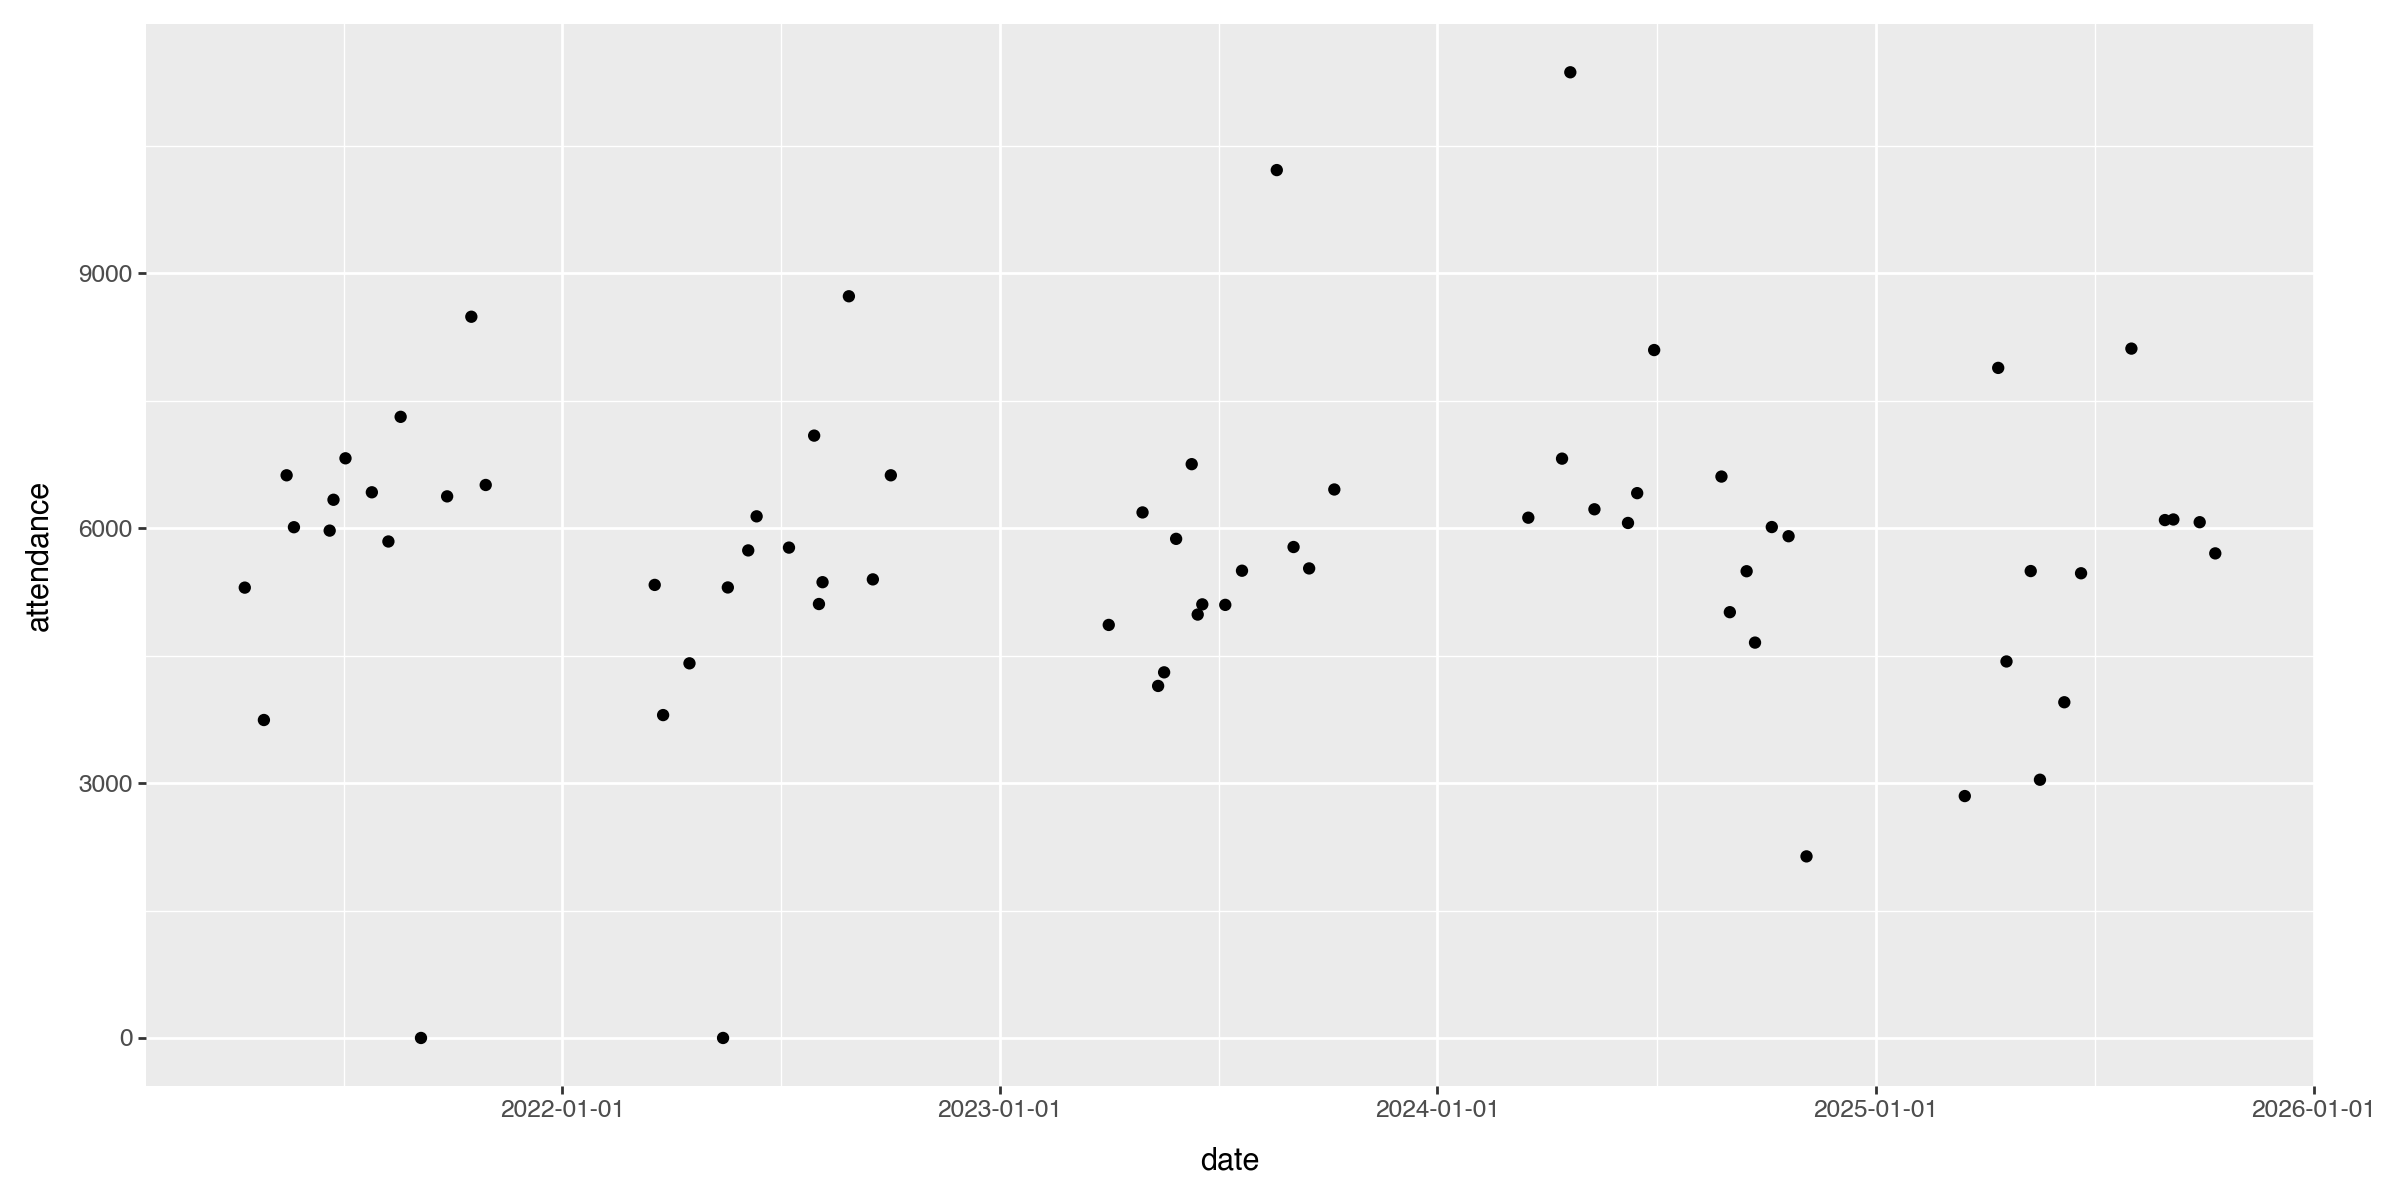

In [6]:
(
    ggplot(
        lynn_games,
        aes(x="date", y="attendance"),
    )
    + geom_point()
    + theme(
        figure_size=(12, 6),
        # axis_text_x=element_text(angle=90),
    )
)